In [1]:
!pip install -q kagglehub tensorflow_hub transformers torch

In [3]:
import kagglehub
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import train_test_split, StratifiedKFold
import os
import time
import pickle
import pandas as pd
from collections import defaultdict

In [4]:
print("="*60)
print("STEP 1: DOWNLOADING DATASET")
print("="*60)

path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print(f"Path to dataset files: {path}")

DATA_DIR = os.path.join(path, "Garbage classification", "Garbage classification")
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
NUM_CLASSES = 6
IMG_SIZE = 224

print(f"\n Dataset downloaded to: {DATA_DIR}")

STEP 1: DOWNLOADING DATASET


100%|██████████| 82.0M/82.0M [00:02<00:00, 32.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/asdasdasasdas/garbage-classification/versions/2

 Dataset downloaded to: /root/.cache/kagglehub/datasets/asdasdasasdas/garbage-classification/versions/2/Garbage classification/Garbage classification


In [5]:
print("\n" + "="*60)
print("VERIFYING DATASET STRUCTURE")
print("="*60)

for class_name in class_names:
    class_dir = os.path.join(DATA_DIR, class_name)
    if os.path.exists(class_dir):
        num_imgs = len([f for f in os.listdir(class_dir) if f.endswith(('.jpg', '.jpeg', '.png'))])
        print(f"  {class_name}: {num_imgs} images")
    else:
        print(f"  {class_name}: NOT FOUND")


VERIFYING DATASET STRUCTURE
  cardboard: 403 images
  glass: 501 images
  metal: 410 images
  paper: 594 images
  plastic: 482 images
  trash: 137 images


In [6]:
print("\n" + "="*60)
print("LOADING ALL IMAGE PATHS")
print("="*60)

file_paths = []
labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_name, img_file))
            labels.append(class_idx)

print(f"Total images: {len(file_paths)}")


LOADING ALL IMAGE PATHS
Total images: 2527


In [7]:
print("\n" + "="*60)
print("STEP 1: 80/20 STRATIFIED SPLIT")
print("="*60)

train_paths, test_paths, train_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

print(f"Training pool (80%): {len(train_paths)} images")
print(f"Test pool (20%): {len(test_paths)} images - ISOLATED")

# Save test set for later
with open('test_set_isolated.pkl', 'wb') as f:
    pickle.dump({'paths': test_paths, 'labels': test_labels, 'class_names': class_names}, f)
print(" Test set saved to 'test_set_isolated.pkl' - DO NOT USE")

# Show distribution
def print_dist(paths, labels, name):
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n{name} distribution:")
    for idx, count in zip(unique, counts):
        print(f"  {class_names[idx]}: {count} ({count/len(labels)*100:.1f}%)")

print_dist(train_paths, train_labels, "Training pool")
print_dist(test_paths, test_labels, "Test pool (isolated)")


STEP 1: 80/20 STRATIFIED SPLIT
Training pool (80%): 2021 images
Test pool (20%): 506 images - ISOLATED
 Test set saved to 'test_set_isolated.pkl' - DO NOT USE

Training pool distribution:
  cardboard: 322 (15.9%)
  glass: 401 (19.8%)
  metal: 328 (16.2%)
  paper: 475 (23.5%)
  plastic: 385 (19.0%)
  trash: 110 (5.4%)

Test pool (isolated) distribution:
  cardboard: 81 (16.0%)
  glass: 100 (19.8%)
  metal: 82 (16.2%)
  paper: 119 (23.5%)
  plastic: 97 (19.2%)
  trash: 27 (5.3%)


In [8]:
print("\n" + "="*60)
print("STEP 2: PREPROCESSING FUNCTIONS")
print("="*60)

def preprocess_image(image_path, label):
    full_path = tf.strings.join([DATA_DIR, "/", image_path])
    image = tf.io.read_file(full_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment_cnn(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    return image, label

def create_cnn_dataset(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_cnn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.one_hot(y, depth=NUM_CLASSES)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

def create_vit_dataset(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_cnn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.cast(y, tf.int32)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

print(" Preprocessing functions ready")


STEP 2: PREPROCESSING FUNCTIONS
 Preprocessing functions ready


In [9]:
print("\n" + "="*60)
print("STEP 3: CNN MODEL BUILDERS")
print("="*60)

from tensorflow.keras import layers

def build_mobilenetv2(num_classes=6, learning_rate=1e-4, weight_decay=0.0001):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base.trainable = False

    model = tf.keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax',
                     kernel_regularizer=tf.keras.regularizers.l2(weight_decay))
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=weight_decay),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def build_resnet50v2(num_classes=6, learning_rate=1e-4, weight_decay=0.0001):
    base = tf.keras.applications.ResNet50V2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base.trainable = False

    model = tf.keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax',
                     kernel_regularizer=tf.keras.regularizers.l2(weight_decay))
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=weight_decay),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print("CNN model builders ready")


STEP 3: CNN MODEL BUILDERS
CNN model builders ready


In [10]:
print("\n" + "="*60)
print("STEP 4: LOADING ViT PRETRAINED WEIGHTS")
print("="*60)

from transformers import ViTModel
import torch

print("Loading pretrained weights from HuggingFace...")
pt_model = ViTModel.from_pretrained('google/vit-base-patch16-224')
pt_model.eval()
pt_weights = {name: param.detach().numpy() for name, param in pt_model.named_parameters()}
print(f"Loaded {len(pt_weights)} weight tensors")


STEP 4: LOADING ViT PRETRAINED WEIGHTS
Loading pretrained weights from HuggingFace...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded 200 weight tensors


In [11]:
print("\n" + "="*60)
print("STEP 5: ViT BUILDING BLOCKS")
print("="*60)

def mlp_block(x, hidden_dim, out_dim, name):
    x = keras.layers.Dense(hidden_dim, activation='gelu', name=f"{name}_fc1")(x)
    x = keras.layers.Dense(out_dim, name=f"{name}_fc2")(x)
    return x

def attention_block(x, num_heads, head_dim, embed_dim, name):
    q = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_q")(x)
    k = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_k")(x)
    v = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_v")(x)

    q = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_q_reshape")(q)
    k = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_k_reshape")(k)
    v = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_v_reshape")(v)

    q = keras.layers.Permute((2, 1, 3), name=f"{name}_q_perm")(q)
    k = keras.layers.Permute((2, 1, 3), name=f"{name}_k_perm")(k)
    v = keras.layers.Permute((2, 1, 3), name=f"{name}_v_perm")(v)

    scale = head_dim ** -0.5
    attn = keras.layers.Lambda(
        lambda qk: keras.ops.softmax(
            keras.ops.matmul(qk[0], keras.ops.transpose(qk[1], (0, 1, 3, 2))) * scale,
            axis=-1
        ),
        name=f"{name}_attn_scores"
    )([q, k])

    out = keras.layers.Lambda(
        lambda av: keras.ops.matmul(av[0], av[1]),
        name=f"{name}_attn_out"
    )([attn, v])

    out = keras.layers.Permute((2, 1, 3), name=f"{name}_out_perm")(out)
    out = keras.layers.Reshape((-1, embed_dim), name=f"{name}_out_reshape")(out)
    out = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_proj")(out)
    return out

def transformer_block(x, num_heads=12, embed_dim=768, mlp_dim=3072, name="block"):
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x)
    y = attention_block(y, num_heads=num_heads, head_dim=embed_dim // num_heads,
                        embed_dim=embed_dim, name=f"{name}_attn")
    x = keras.layers.Add()([x, y])
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    y = mlp_block(y, hidden_dim=mlp_dim, out_dim=embed_dim, name=f"{name}_mlp")
    x = keras.layers.Add()([x, y])
    return x

print("ViT building blocks ready")


STEP 5: ViT BUILDING BLOCKS
ViT building blocks ready


In [12]:
print("\n" + "="*60)
print("STEP 6: BUILDING ViT MODEL")
print("="*60)

def build_vit_model(num_classes=6, learning_rate=2e-5, weight_decay=0.01):
    num_patches = (IMG_SIZE // 16) ** 2
    seq_len = num_patches + 1
    embed_dim = 768
    num_heads = 12
    mlp_dim = 3072
    num_layers = 12

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="pixel_values")

    patches = keras.layers.Conv2D(
        filters=embed_dim, kernel_size=16, strides=16,
        padding='valid', use_bias=True, name="patch_embed_proj"
    )(inputs)
    patches = keras.layers.Reshape((num_patches, embed_dim), name="patch_embed_reshape")(patches)

    class CLSToken(keras.layers.Layer):
        def build(self, input_shape):
            self.cls = self.add_weight(
                name="cls", shape=(1, 1, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return keras.ops.broadcast_to(self.cls, (keras.ops.shape(x)[0], 1, embed_dim))

    cls_tokens = CLSToken(name="cls_token")(patches)
    x = keras.layers.Concatenate(axis=1, name="cls_concat")([cls_tokens, patches])

    class PosEmbed(keras.layers.Layer):
        def build(self, input_shape):
            self.pos = self.add_weight(
                name="pos", shape=(1, seq_len, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return x + self.pos

    x = PosEmbed(name="pos_embed")(x)

    for i in range(num_layers):
        x = transformer_block(x, num_heads=num_heads, embed_dim=embed_dim,
                               mlp_dim=mlp_dim, name=f"block_{i}")

    x = keras.layers.LayerNormalization(epsilon=1e-6, name="ln_final")(x)
    cls_out = keras.layers.Lambda(lambda t: t[:, 0, :], name="cls_extract")(x)

    z = keras.layers.Dense(256, activation='relu', name="head_dense")(cls_out)
    z = keras.layers.Dropout(0.3, name="head_dropout")(z)
    outputs = keras.layers.Dense(num_classes, name="head_out")(z)

    vit_model = keras.Model(inputs=inputs, outputs=outputs)

    # Transfer pretrained weights
    print("Transferring pretrained weights...")

    def get_pt(key):
        return pt_weights[key]

    vit_model.get_layer("patch_embed_proj").set_weights([
        np.transpose(get_pt("embeddings.patch_embeddings.projection.weight"), (2, 3, 1, 0)),
        get_pt("embeddings.patch_embeddings.projection.bias")
    ])
    vit_model.get_layer("cls_token").set_weights([
        get_pt("embeddings.cls_token").reshape(1, 1, 768)
    ])
    vit_model.get_layer("pos_embed").set_weights([
        get_pt("embeddings.position_embeddings").reshape(1, 197, 768)
    ])

    for i in range(12):
        p = f"layers.{i}"
        vit_model.get_layer(f"block_{i}_ln1").set_weights([
            get_pt(f"{p}.layernorm_before.weight"),
            get_pt(f"{p}.layernorm_before.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_q").set_weights([
            get_pt(f"{p}.attention.q_proj.weight").T,
            get_pt(f"{p}.attention.q_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_k").set_weights([
            get_pt(f"{p}.attention.k_proj.weight").T,
            get_pt(f"{p}.attention.k_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_v").set_weights([
            get_pt(f"{p}.attention.v_proj.weight").T,
            get_pt(f"{p}.attention.v_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_proj").set_weights([
            get_pt(f"{p}.attention.o_proj.weight").T,
            get_pt(f"{p}.attention.o_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_ln2").set_weights([
            get_pt(f"{p}.layernorm_after.weight"),
            get_pt(f"{p}.layernorm_after.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc1").set_weights([
            get_pt(f"{p}.mlp.fc1.weight").T,
            get_pt(f"{p}.mlp.fc1.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc2").set_weights([
            get_pt(f"{p}.mlp.fc2.weight").T,
            get_pt(f"{p}.mlp.fc2.bias")
        ])

    vit_model.get_layer("ln_final").set_weights([
        get_pt("layernorm.weight"),
        get_pt("layernorm.bias")
    ])
    print(" Pretrained weights transferred")

    # Freeze backbone
    backbone_layers = [l for l in vit_model.layers if not l.name.startswith("head_")]
    for layer in backbone_layers:
        layer.trainable = False

    vit_model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=weight_decay
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    trainable = sum([tf.size(v).numpy() for v in vit_model.trainable_variables])
    non_trainable = sum([tf.size(v).numpy() for v in vit_model.non_trainable_variables])
    print(f"Trainable:     {trainable:,}")
    print(f"Non-trainable: {non_trainable:,}")
    print(f"Total:         {trainable + non_trainable:,}")

    return vit_model

print("ViT model builder ready")


STEP 6: BUILDING ViT MODEL
ViT model builder ready


In [ ]:
print("\n" + "="*60)
print("STEP 7: CROSS-VALIDATION FUNCTION")
print("="*60)

def cross_validate_model(model_builder, model_name, train_paths, train_labels,
                          batch_size, is_vit=False, num_folds=5):

    from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

    skf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=42)

    fold_metrics = {
        'macro_f1': [], 'accuracy': [], 'precision': [], 'recall': [],
        'latency_ms': [], 'history': []
    }

    for fold, (train_idx, val_idx) in enumerate(skf.split(train_paths, train_labels)):
        print(f"\n{'='*50}")
        print(f"Fold {fold+1}/{num_folds} - {model_name}")
        print(f"{'='*50}")

        fold_train_paths = [train_paths[i] for i in train_idx]
        fold_train_labels = [train_labels[i] for i in train_idx]
        fold_val_paths = [train_paths[i] for i in val_idx]
        fold_val_labels = [train_labels[i] for i in val_idx]

        print(f"Train: {len(fold_train_paths)}, Val: {len(fold_val_paths)}")

        if is_vit:
            train_ds = create_vit_dataset(fold_train_paths, fold_train_labels, batch_size, augment=True)
            val_ds = create_vit_dataset(fold_val_paths, fold_val_labels, batch_size, augment=False)
        else:
            train_ds = create_cnn_dataset(fold_train_paths, fold_train_labels, batch_size, augment=True)
            val_ds = create_cnn_dataset(fold_val_paths, fold_val_labels, batch_size, augment=False)

        model = model_builder()

        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True, verbose=0
        )
        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, verbose=0
        )

        def measure_latency(model, dataset, num_samples=100):
            latencies = []
            for images, _ in dataset.take(1):
                images = images[:min(num_samples, len(images))]
                for i in range(len(images)):
                    single_img = images[i:i+1]
                    start = time.perf_counter()
                    _ = model.predict(single_img, verbose=0)
                    latencies.append((time.perf_counter() - start) * 1000)
            return np.mean(latencies)

        history = model.fit(
            train_ds, validation_data=val_ds, epochs=20,
            callbacks=[early_stop, reduce_lr], verbose=1
        )

        y_true, y_pred = [], []
        for images, labels in val_ds:
            preds = model.predict(images, verbose=0)
            if is_vit:
                y_true.extend(labels.numpy())
                y_pred.extend(np.argmax(preds, axis=1))
            else:
                y_true.extend(np.argmax(labels.numpy(), axis=1))
                y_pred.extend(np.argmax(preds, axis=1))

        macro_f1 = f1_score(y_true, y_pred, average='macro')
        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(y_true, y_pred, average='macro')
        recall = recall_score(y_true, y_pred, average='macro')
        latency = measure_latency(model, val_ds)

        fold_metrics['macro_f1'].append(macro_f1)
        fold_metrics['accuracy'].append(accuracy)
        fold_metrics['precision'].append(precision)
        fold_metrics['recall'].append(recall)
        fold_metrics['latency_ms'].append(latency)
        fold_metrics['history'].append(history)

        print(f"Fold {fold+1} - F1: {macro_f1:.4f}, Acc: {accuracy:.4f}")

    print(f"\n{'='*50}")
    print(f"{model_name} - 5-Fold CV Results")
    print(f"{'='*50}")
    print(f"Macro F1:  {np.mean(fold_metrics['macro_f1']):.4f} ± {np.std(fold_metrics['macro_f1']):.4f}")
    print(f"Accuracy:  {np.mean(fold_metrics['accuracy']):.4f} ± {np.std(fold_metrics['accuracy']):.4f}")
    print(f"Latency:   {np.mean(fold_metrics['latency_ms']):.2f} ± {np.std(fold_metrics['latency_ms']):.2f} ms")

    return fold_metrics

print("Cross-validation function ready")


STEP 7: CROSS-VALIDATION FUNCTION
Cross-validation function ready


In [ ]:
print("\n" + "="*60)
print("STEP 8: PHASE 1 - 5-FOLD CROSS-VALIDATION")
print("="*60)

# Configs
batch_size_mobilenet = 32
batch_size_resnet = 32
batch_size_vit = 16

# MobileNetV2
print("\n" + "="*60)
print("STARTING 5-FOLD CV: MobileNetV2")
print("="*60)
mobilenet_results = cross_validate_model(
    lambda: build_mobilenetv2(NUM_CLASSES), "MobileNetV2",
    train_paths, train_labels, batch_size_mobilenet, is_vit=False
)

# ResNet50V2
print("\n" + "="*60)
print("STARTING 5-FOLD CV: ResNet50V2")
print("="*60)
resnet_results = cross_validate_model(
    lambda: build_resnet50v2(NUM_CLASSES), "ResNet50V2",
    train_paths, train_labels, batch_size_resnet, is_vit=False
)

# ViT
print("\n" + "="*60)
print("STARTING 5-FOLD CV: ViT")
print("="*60)
vit_results = cross_validate_model(
    lambda: build_vit_model(NUM_CLASSES), "ViT",
    train_paths, train_labels, batch_size_vit, is_vit=True
)

print("\n Phase 1 Cross-Validation Complete!")


STEP 8: PHASE 1 - 5-FOLD CROSS-VALIDATION

STARTING 5-FOLD CV: MobileNetV2

Fold 1/5 - MobileNetV2
Train: 1616, Val: 405
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 61s 733ms/step - accuracy: 0.2500 - loss: 1.9112 - val_accuracy: 0.3407 - val_loss: 1.5838 - learning_rate: 1.0000e-04
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.3645 - loss: 1.6402 - val_accuracy: 0.4321 - val_loss: 1.3981 - learning_rate: 1.0000e-04
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.4325 - loss: 1.4698 - val_accuracy: 0.5111 - val_loss: 1.2623 - learning_rate: 1.0000e-04
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.4901 - loss: 1.3160 - val_accuracy: 0.5556 - val_loss: 1.1577 - learning_rate: 1.0000e-04
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.5489 - loss: 1.2005 - val_accuracy: 0.6148 - val_loss: 1.0756 - learning_rate: 1.0000e-04
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step -

In [ ]:
print("\n" + "="*60)
print("STEP 9: SAVING PHASE 1 RESULTS")
print("="*60)

results_df = pd.DataFrame({
    'Model': ['MobileNetV2', 'ResNet50V2', 'ViT'],
    'Macro F1 (mean±std)': [
        f"{np.mean(mobilenet_results['macro_f1']):.4f} ± {np.std(mobilenet_results['macro_f1']):.4f}",
        f"{np.mean(resnet_results['macro_f1']):.4f} ± {np.std(resnet_results['macro_f1']):.4f}",
        f"{np.mean(vit_results['macro_f1']):.4f} ± {np.std(vit_results['macro_f1']):.4f}"
    ],
    'Accuracy': [
        f"{np.mean(mobilenet_results['accuracy']):.4f}",
        f"{np.mean(resnet_results['accuracy']):.4f}",
        f"{np.mean(vit_results['accuracy']):.4f}"
    ],
    'Latency (ms)': [
        f"{np.mean(mobilenet_results['latency_ms']):.2f}",
        f"{np.mean(resnet_results['latency_ms']):.2f}",
        f"{np.mean(vit_results['latency_ms']):.2f}"
    ]
})

print(results_df.to_string(index=False))
results_df.to_csv('phase1_cv_results.csv', index=False)
print("\n Phase 1 results saved to 'phase1_cv_results.csv'")

# Save raw results
phase1_raw = {
    'mobilenet': {
        'macro_f1': mobilenet_results['macro_f1'],
        'accuracy': mobilenet_results['accuracy'],
        'precision': mobilenet_results['precision'],
        'recall': mobilenet_results['recall'],
        'latency_ms': mobilenet_results['latency_ms']
    },
    'resnet': {
        'macro_f1': resnet_results['macro_f1'],
        'accuracy': resnet_results['accuracy'],
        'precision': resnet_results['precision'],
        'recall': resnet_results['recall'],
        'latency_ms': resnet_results['latency_ms']
    },
    'vit': {
        'macro_f1': vit_results['macro_f1'],
        'accuracy': vit_results['accuracy'],
        'precision': vit_results['precision'],
        'recall': vit_results['recall'],
        'latency_ms': vit_results['latency_ms']
    }
}

with open('phase1_raw_results.pkl', 'wb') as f:
    pickle.dump(phase1_raw, f)
print(" Raw results saved to 'phase1_raw_results.pkl'")

In [13]:
print("\n" + "="*60)
print("STEP 10: CREATING 90/10 SPLIT FOR FINAL TRAINING")
print("="*60)

train_paths_final, val_paths_final, train_labels_final, val_labels_final = train_test_split(
    train_paths, train_labels,
    test_size=0.1,
    stratify=train_labels,
    random_state=42
)

print(f"Final Train (90% of 80% pool): {len(train_paths_final)} images")
print(f"Final Val (10% of 80% pool): {len(val_paths_final)} images")
print(f"Test Set (20% isolated): {len(test_paths)} images")

# Show distribution
print_dist(train_paths_final, train_labels_final, "Final Train")
print_dist(val_paths_final, val_labels_final, "Final Val")


STEP 10: CREATING 90/10 SPLIT FOR FINAL TRAINING
Final Train (90% of 80% pool): 1818 images
Final Val (10% of 80% pool): 203 images
Test Set (20% isolated): 506 images

Final Train distribution:
  cardboard: 290 (16.0%)
  glass: 361 (19.9%)
  metal: 295 (16.2%)
  paper: 427 (23.5%)
  plastic: 346 (19.0%)
  trash: 99 (5.4%)

Final Val distribution:
  cardboard: 32 (15.8%)
  glass: 40 (19.7%)
  metal: 33 (16.3%)
  paper: 48 (23.6%)
  plastic: 39 (19.2%)
  trash: 11 (5.4%)


In [14]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - MobileNetV2")
print("="*60)

MOBILENET_CONFIG = {
    'learning_rate': 1e-4,
    'batch_size': 32,
    'weight_decay': 0.0001
}

print(f"Config: LR={MOBILENET_CONFIG['learning_rate']}, "
      f"Batch={MOBILENET_CONFIG['batch_size']}, WD={MOBILENET_CONFIG['weight_decay']}")

# Create datasets
train_ds_mobilenet = create_cnn_dataset(
    train_paths_final, train_labels_final,
    MOBILENET_CONFIG['batch_size'],
    augment=True
)
val_ds_mobilenet = create_cnn_dataset(
    val_paths_final, val_labels_final,
    MOBILENET_CONFIG['batch_size'],
    augment=False
)

# Build model
mobilenet_final = build_mobilenetv2(
    num_classes=NUM_CLASSES,
    learning_rate=MOBILENET_CONFIG['learning_rate'],
    weight_decay=MOBILENET_CONFIG['weight_decay']
)

# Callbacks
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
)
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'mobilenet_final_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train
history_mobilenet_final = mobilenet_final.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    epochs=30,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

mobilenet_final.save('mobilenet_final_model.keras')
print("MobileNetV2 final model saved")


PHASE 2: FINAL TRAINING - MobileNetV2
Config: LR=0.0001, Batch=32, WD=0.0001
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.1833 - loss: 2.0699
Epoch 1: val_accuracy improved from None to 0.32512, saving model to mobilenet_final_best.keras

Epoch 1: finished saving model to mobilenet_final_best.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 62s 591ms/step - accuracy: 0.2184 - loss: 1.9598 - val_accuracy: 0.3251 - val_loss: 1.6222 - learning_rate: 1.0000e-04
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.3463 - loss: 1.7030
Epoch 2: val_accuracy improved from 0.32512 to 0.45813, saving model to mobilenet_final_best.keras

Epoch 2: finished saving model to mobilenet_final_best.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.3702 - loss: 1.6271 - val_accuracy: 0.4581 - val_loss: 1.3955 - learning_rate: 1.0000e-04
Epoch 3/30
56/57 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.4273 - loss: 1.4621
Epoch 3:

In [15]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - ResNet50V2")
print("="*60)

RESNET_CONFIG = {
    'learning_rate': 1e-4,
    'batch_size': 32,
    'weight_decay': 0.0001
}

print(f"Config: LR={RESNET_CONFIG['learning_rate']}, "
      f"Batch={RESNET_CONFIG['batch_size']}, WD={RESNET_CONFIG['weight_decay']}")

# Create datasets
train_ds_resnet = create_cnn_dataset(
    train_paths_final, train_labels_final,
    RESNET_CONFIG['batch_size'],
    augment=True
)
val_ds_resnet = create_cnn_dataset(
    val_paths_final, val_labels_final,
    RESNET_CONFIG['batch_size'],
    augment=False
)

# Build model
resnet_final = build_resnet50v2(
    num_classes=NUM_CLASSES,
    learning_rate=RESNET_CONFIG['learning_rate'],
    weight_decay=RESNET_CONFIG['weight_decay']
)

# Train
history_resnet_final = resnet_final.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    epochs=30,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

resnet_final.save('resnet_final_model.keras')
print("ResNet50V2 final model saved")


PHASE 2: FINAL TRAINING - ResNet50V2
Config: LR=0.0001, Batch=32, WD=0.0001
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.2165 - loss: 2.2340
Epoch 1: val_accuracy did not improve from 0.79803
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 339ms/step - accuracy: 0.2453 - loss: 2.1015 - val_accuracy: 0.3251 - val_loss: 1.6782 - learning_rate: 1.0000e-04
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.3576 - loss: 1.7587
Epoch 2: val_accuracy did not improve from 0.79803
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.3878 - loss: 1.6781 - val_accuracy: 0.4631 - val_loss: 1.3777 - learning_rate: 1.0000e-04
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.4773 - loss: 1.4463
Epoch 3: val_accuracy did not improve from 0.79803
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.4791 - loss: 1.3858 - val_accuracy: 0.5468 - val_loss: 1.1873 - learning_rate: 1.0000e-04
Epoch 4/30
57/57 ━━━━━━━━━━━━

In [16]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - ViT (50% Unfreeze)")
print("="*60)

import gc
gc.collect()
tf.keras.backend.clear_session()
print(" Memory cleared")

VIT_CONFIG = {
    'learning_rate': 2e-5,
    'batch_size': 16,
    'weight_decay': 0.01
}

print(f"Config: LR={VIT_CONFIG['learning_rate']}, "
      f"Batch={VIT_CONFIG['batch_size']}, WD={VIT_CONFIG['weight_decay']}")

# Create datasets
train_ds_vit = create_vit_dataset(
    train_paths_final, train_labels_final,
    VIT_CONFIG['batch_size'],
    augment=True
)
val_ds_vit = create_vit_dataset(
    val_paths_final, val_labels_final,
    VIT_CONFIG['batch_size'],
    augment=False
)

# Build fresh model
vit_model_phase2 = build_vit_model(
    num_classes=NUM_CLASSES,
    learning_rate=VIT_CONFIG['learning_rate'],
    weight_decay=VIT_CONFIG['weight_decay']
)

# Stage 1: Train Frozen Backbone
print("\n" + "-"*40)
print("STAGE 1: Training Frozen Backbone")
print("-"*40)

history_vit_stage1 = vit_model_phase2.fit(
    train_ds_vit,
    validation_data=val_ds_vit,
    epochs=30,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

vit_model_phase2.save('vit_stage1_model.keras')
print(" ViT Stage 1 model saved")

# Stage 2: Unfreeze 50%
print("\n" + "-"*40)
print("STAGE 2: Unfreezing Last 50% of Transformer Blocks")
print("-"*40)

transformer_blocks = []
for layer in vit_model_phase2.layers:
    if layer.name.startswith("block_"):
        transformer_blocks.append(layer)

num_blocks = len(transformer_blocks)
num_to_unfreeze = int(num_blocks * 0.5)
unfrozen_blocks = transformer_blocks[-num_to_unfreeze:]

print(f"Unfreezing last {num_to_unfreeze} blocks ({num_to_unfreeze/num_blocks*100:.0f}%)")

for block in unfrozen_blocks:
    block.trainable = True

# Recompile with lower LR
STAGE2_LR = 1e-5
vit_model_phase2.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=STAGE2_LR,
        weight_decay=0.01
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Train Stage 2
history_vit_stage2 = vit_model_phase2.fit(
    train_ds_vit,
    validation_data=val_ds_vit,
    epochs=20,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

vit_model_phase2.save('vit_final_50percent.keras')
print("ViT final model (50% unfreeze) saved")


PHASE 2: FINAL TRAINING - ViT (50% Unfreeze)
 Memory cleared
Config: LR=2e-05, Batch=16, WD=0.01
Transferring pretrained weights...
 Pretrained weights transferred
Trainable:     198,406
Non-trainable: 85,798,658
Total:         85,997,064

----------------------------------------
STAGE 1: Training Frozen Backbone
----------------------------------------
Epoch 1/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.1752 - loss: 2.3355
Epoch 1: val_accuracy did not improve from 0.79803
114/114 ━━━━━━━━━━━━━━━━━━━━ 55s 327ms/step - accuracy: 0.2305 - loss: 2.0897 - val_accuracy: 0.3744 - val_loss: 1.5641 - learning_rate: 2.0000e-05
Epoch 2/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.3936 - loss: 1.5696
Epoch 2: val_accuracy did not improve from 0.79803
114/114 ━━━━━━━━━━━━━━━━━━━━ 25s 216ms/step - accuracy: 0.4384 - loss: 1.4442 - val_accuracy: 0.6010 - val_loss: 1.1621 - learning_rate: 2.0000e-05
Epoch 3/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.5

In [17]:
print("\n" + "="*60)
print("STEP 11: FINAL TEST EVALUATION - ALL MODELS")
print("="*60)

# Load test set
with open('test_set_isolated.pkl', 'rb') as f:
    test_data = pickle.load(f)

test_paths = test_data['paths']
test_labels = test_data['labels']

print(f"Test set: {len(test_paths)} images")

# Create test dataset (batch size 32 for CNNs, 16 for ViT)
test_ds_cnn = create_cnn_dataset(test_paths, test_labels, batch_size=32, augment=False)
test_ds_vit = create_vit_dataset(test_paths, test_labels, batch_size=16, augment=False)

def evaluate_on_test(model, model_name, test_ds, is_vit=False):
    print(f"\n{'='*60}")
    print(f"Evaluating {model_name} on Test Set")
    print('='*60)

    y_true, y_pred = [], []
    for images, labels in test_ds:
        preds = model.predict(images, verbose=0)
        if is_vit:
            y_true.extend(labels.numpy())
            y_pred.extend(np.argmax(preds, axis=1))
        else:
            y_true.extend(np.argmax(labels.numpy(), axis=1))
            y_pred.extend(np.argmax(preds, axis=1))

    print(classification_report(y_true, y_pred, target_names=class_names))

    macro_f1 = f1_score(y_true, y_pred, average='macro')
    accuracy = accuracy_score(y_true, y_pred)

    print(f"\n {model_name} - Test Results:")
    print(f"   Macro F1: {macro_f1:.4f}")
    print(f"   Accuracy: {accuracy:.4f}")

    return {'macro_f1': macro_f1, 'accuracy': accuracy, 'y_true': y_true, 'y_pred': y_pred}

# Evaluate all models
mobilenet_test = evaluate_on_test(mobilenet_final, "MobileNetV2", test_ds_cnn, is_vit=False)
resnet_test = evaluate_on_test(resnet_final, "ResNet50V2", test_ds_cnn, is_vit=False)
vit_test = evaluate_on_test(vit_model_phase2, "ViT (50% Unfreeze)", test_ds_vit, is_vit=True)

# Save results
with open('final_test_results.pkl', 'wb') as f:
    pickle.dump({
        'mobilenet': mobilenet_test,
        'resnet': resnet_test,
        'vit': vit_test
    }, f)
print("\n Final test results saved to 'final_test_results.pkl'")


STEP 11: FINAL TEST EVALUATION - ALL MODELS
Test set: 506 images

Evaluating MobileNetV2 on Test Set
              precision    recall  f1-score   support

   cardboard       0.95      0.89      0.92        81
       glass       0.75      0.73      0.74       100
       metal       0.79      0.83      0.81        82
       paper       0.84      0.89      0.87       119
     plastic       0.73      0.79      0.76        97
       trash       0.60      0.33      0.43        27

    accuracy                           0.80       506
   macro avg       0.78      0.74      0.75       506
weighted avg       0.80      0.80      0.80       506


 MobileNetV2 - Test Results:
   Macro F1: 0.7534
   Accuracy: 0.8004

Evaluating ResNet50V2 on Test Set
              precision    recall  f1-score   support

   cardboard       0.60      0.60      0.60        81
       glass       0.35      0.46      0.40       100
       metal       0.11      0.07      0.09        82
       paper       0.48      0.50

In [18]:
print("\n" + "="*60)
print("FINAL MODEL COMPARISON - TEST SET")
print("="*60)

comparison_df = pd.DataFrame({
    'Model': ['MobileNetV2', 'ResNet50V2', 'ViT (50% Unfreeze)'],
    'Macro F1': [
        f"{mobilenet_test['macro_f1']:.4f}",
        f"{resnet_test['macro_f1']:.4f}",
        f"{vit_test['macro_f1']:.4f}"
    ],
    'Accuracy': [
        f"{mobilenet_test['accuracy']:.4f}",
        f"{resnet_test['accuracy']:.4f}",
        f"{vit_test['accuracy']:.4f}"
    ]
})

print(comparison_df.to_string(index=False))
comparison_df.to_csv('final_comparison_results.csv', index=False)
print("\n Final comparison saved to 'final_comparison_results.csv'")


FINAL MODEL COMPARISON - TEST SET
             Model Macro F1 Accuracy
       MobileNetV2   0.7534   0.8004
        ResNet50V2   0.3001   0.3617
ViT (50% Unfreeze)   0.9022   0.9249

 Final comparison saved to 'final_comparison_results.csv'



CONFUSION MATRICES - ALL MODELS


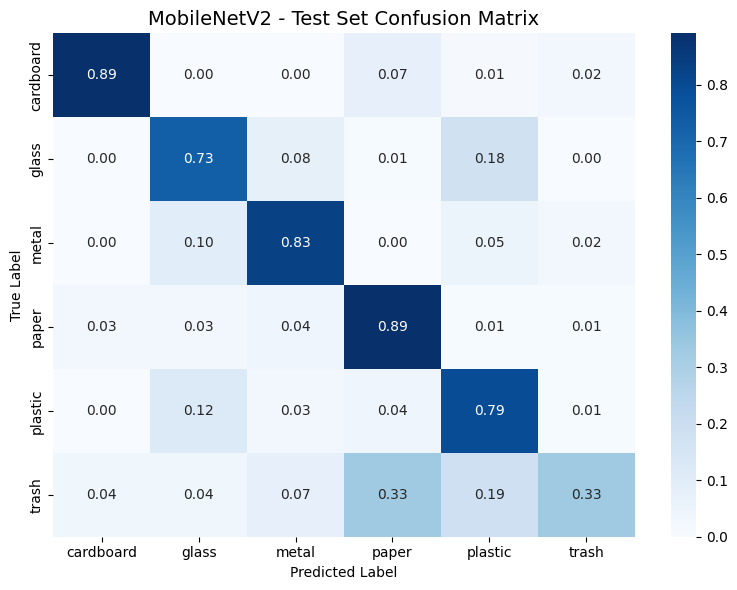

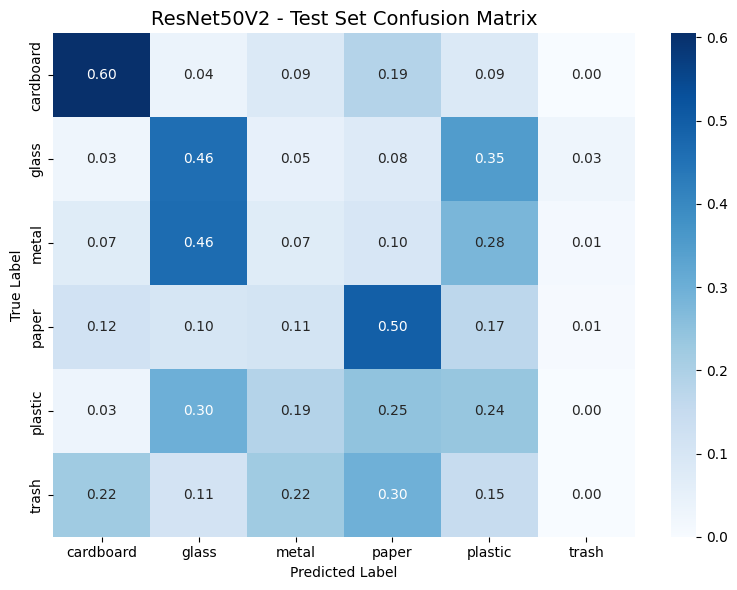

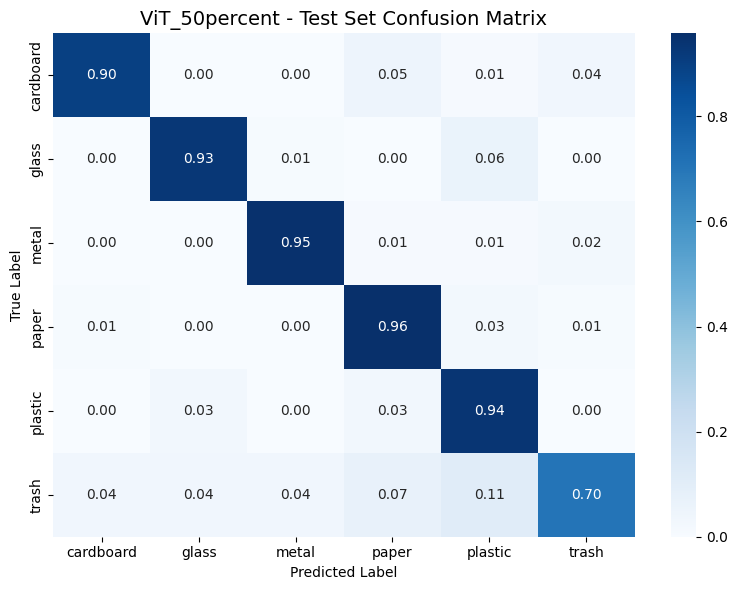

In [19]:
print("\n" + "="*60)
print("CONFUSION MATRICES - ALL MODELS")
print("="*60)

def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model_name} - Test Set Confusion Matrix', fontsize=14)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'{model_name.lower()}_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_confusion_matrix(mobilenet_test['y_true'], mobilenet_test['y_pred'], "MobileNetV2")
plot_confusion_matrix(resnet_test['y_true'], resnet_test['y_pred'], "ResNet50V2")
plot_confusion_matrix(vit_test['y_true'], vit_test['y_pred'], "ViT_50percent")

In [21]:
print("\n" + "="*60)
print("SUMMARY - FULL PIPELINE")
print("="*60)

print("\n PHASE 1 - 5-Fold Cross-Validation Results:")
print(results_df.to_string(index=False))

print("\n PHASE 2 - Final Test Results:")
print(comparison_df.to_string(index=False))

print("\n BEST MODEL: ViT (50% Unfreeze)")
print(f"   Test Accuracy: {vit_test['accuracy']:.4f}")
print(f"   Test Macro F1: {vit_test['macro_f1']:.4f}")

print("\n All files saved:")
print("   - phase1_cv_results.csv")
print("   - phase1_raw_results.pkl")
print("   - mobilenet_final_model.keras")
print("   - resnet_final_model.keras")
print("   - vit_final_50percent.keras")
print("   - final_test_results.pkl")
print("   - final_comparison_results.csv")
print("   - *_confusion_matrix.png")

print("\n" + "="*60)
print(" FULL PIPELINE COMPLETE!")
print("="*60)


SUMMARY - FULL PIPELINE

 PHASE 2 - Final Test Results:
             Model Macro F1 Accuracy
       MobileNetV2   0.7534   0.8004
        ResNet50V2   0.3001   0.3617
ViT (50% Unfreeze)   0.9022   0.9249

 BEST MODEL: ViT (50% Unfreeze)
   Test Accuracy: 0.9249
   Test Macro F1: 0.9022

 All files saved:
   - phase1_cv_results.csv
   - phase1_raw_results.pkl
   - mobilenet_final_model.keras
   - resnet_final_model.keras
   - vit_final_50percent.keras
   - final_test_results.pkl
   - final_comparison_results.csv
   - *_confusion_matrix.png

 FULL PIPELINE COMPLETE!
